(composition)=
# Cell-type composition

Test whether a condition changes the share of each cell type in the samples with
{api}`propeller`, as speckle does [@phipson2022], from the numbers of cells that a cube
records for every sample and cell type. The simulated PBMC study
knows the answer: 12 donors, each sampled before and after a stimulation that
multiplies the ratio of monocytes to every other cell type by $e^{0.7}$, about 2, and
changes nothing else (the `simulated_pbmc` dataset of the
[Datasets](../reference/datasets.md) page). [Composition
tests](../statistics/composition.md#propeller-steps) gives propeller's steps.

CytePool 0.1.dev70+g194507939
Cube with 24 samples x 6 groups x 2,000 features
  layers: counts (uint32, lazy), detected (uint32, lazy), log_sum (float64,
          lazy), log_sum_sq (float64, lazy), linear_sum (float64, lazy)
  filled: 144 of 144 sample x group entries have cells (100.0%)
  samples: sample_id, donor, condition, sex
  groups: group_id
  features: feature_id, symbol


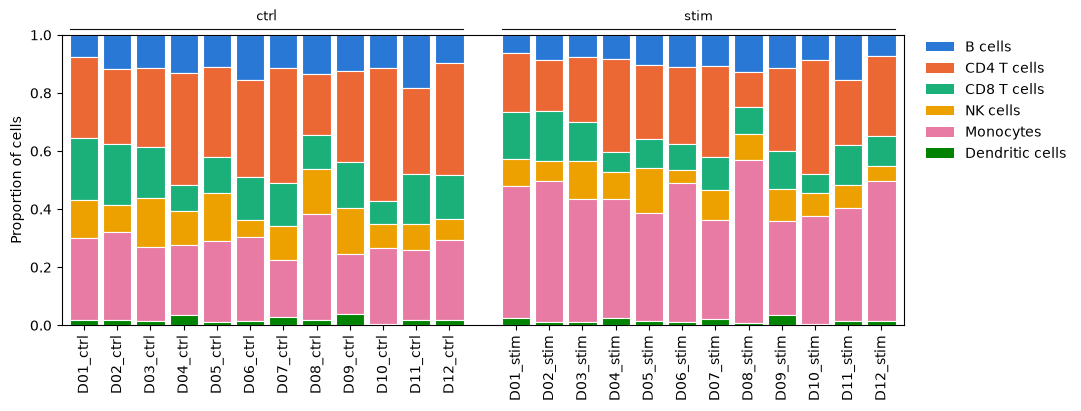

In [1]:
import matplotlib.pyplot as plt

import cytepool
from cytepool import Design, propeller, read_cube
from cytepool.plotting import plot_composition, plot_proportions

cube = read_cube("simulated_pbmc.cube.zarr")
print(f"CytePool {cytepool.__version__}")
print(cube)
plot_composition(cube, by="condition")
plt.show()

## Test every cell type

Each donor gives a sample in each condition, so the design pairs them, as for the
genes ([Genes that change in each cell type](genes_per_cell_type.ipynb)); propeller
fits fixed effects, and the donor enters the formula. It reads the cube's cell numbers
({api}`Cube.n_cells`), and the table of a contrast gives each cell type's baseline
proportion, its mean proportion in each condition, their ratio and the moderated
t-test.

B cells          stimulated / control 0.81, adjusted p-value 6.4e-05
CD4 T cells      stimulated / control 0.78, adjusted p-value 1.7e-07
CD8 T cells      stimulated / control 0.77, adjusted p-value 3.6e-07
NK cells         stimulated / control 0.78, adjusted p-value 1.2e-05
Monocytes        stimulated / control 1.60, adjusted p-value 4.6e-12
Dendritic cells  stimulated / control 0.81, adjusted p-value 0.0052


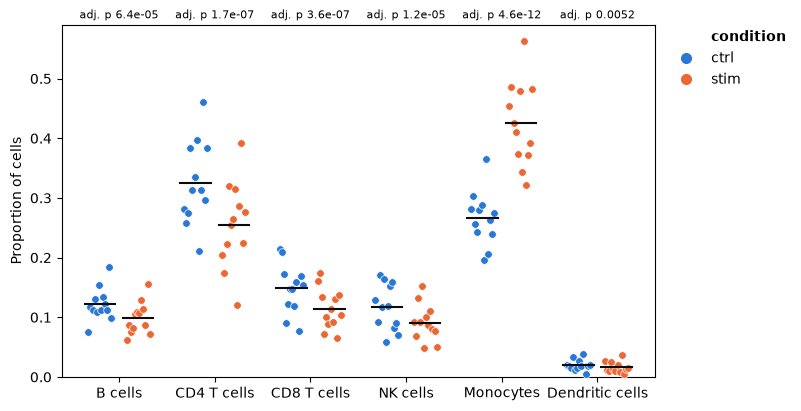

In [2]:
design = Design(
    cube.samples,
    "~ donor + condition",
    levels={"condition": ["ctrl", "stim"]},
    contrasts={"stim_vs_ctrl": "conditionstim"},
)
result = propeller(cube, design)
table = result.table("stim_vs_ctrl")
for group, ratio, adjusted in zip(
    table["group_id"], table["proportion_ratio"], table["adjusted_p_value"]
):
    print(
        f"{group:<16} stimulated / control {ratio:.2f}, adjusted p-value {adjusted:.2g}"
    )
plot_proportions(result, by="condition")
plt.show()

Every cell type tests significant, although the simulation changed only the
monocytes: proportions add up to one, so when the monocytes gain, the shares of all
the others fall. The ratios show what happened: the five other cell types fall by
about the same factor, 0.77 to 0.81, which is what a rise of the monocytes alone does
to them.

## Test within a lineage

The denominator decides the question. Among the lymphocytes alone, the B, T and NK
cells, a rise of the monocytes does not move the shares, and the test asks whether the
stimulation changes the lymphocytes' make-up. {api}`Cube.select` keeps those cell
types.

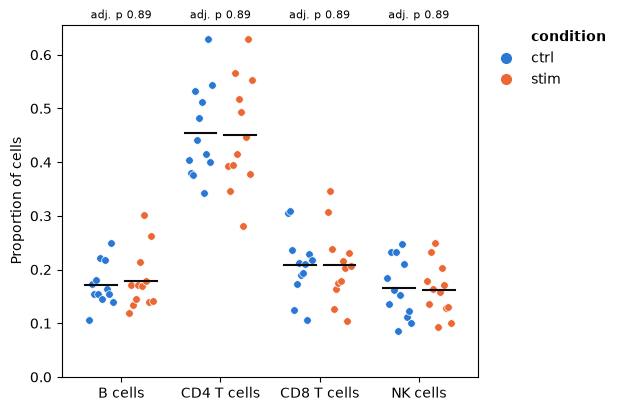

In [3]:
lymphocytes = cube.select(groups=["B cells", "CD4 T cells", "CD8 T cells", "NK cells"])
within = propeller(lymphocytes, design)
plot_proportions(within, by="condition")
plt.show()

Within the lymphocytes nothing changes, as simulated: the rise of the monocytes
lowered the lymphocytes' share of all cells, not their make-up.

## Choices

- **The design.** Pair the samples of a donor when each donor gives one in every
  condition; propeller refuses random effects, so the donor is a fixed effect. Without
  the pairing, the differences between donors' compositions count as noise, as below.
- **The denominator.** Proportions are shares of the cell types tested: a change in one
  cell type moves the shares of all the others. Test the cell types of one lineage
  with {api}`Cube.select` when the question is about that lineage, as above, and read
  the proportion ratios of the result, not only its p-values.
- **The transform.** The logit, speckle's default, or `transform="asin"`; they agree
  on clear changes, as below.
- **Robust moderation.** On by default, as in speckle. It changes the prior only with
  10 cell types or more, so with the six cell types here the results are those of
  `robust=False` ([Moderation across cell
  types](../statistics/composition.md#composition-moderation)).
- **Several conditions.** `f_tests="condition"` tests every level of the condition at
  once, and {api}`plot_proportions` then shows the F-test's adjusted p-values.
- **Not yet available.** Precision-weighted mixed models and count models of
  composition ([Composition tests](../statistics/composition.md#composition-limits)).

### The design and the transform

The paired design and the logit, the defaults above, against the arcsine square root and
a design without the pairing:

In [4]:
unpaired = Design(
    cube.samples,
    "~ condition",
    levels={"condition": ["ctrl", "stim"]},
    contrasts={"stim_vs_ctrl": "conditionstim"},
)
tests = {
    "paired, logit": propeller(cube, design),
    "paired, asin": propeller(cube, design, transform="asin"),
    "unpaired, logit": propeller(cube, unpaired),
}
tables = {name: test.table("stim_vs_ctrl") for name, test in tests.items()}
print("adjusted p-values of the stimulation")
print(f"{'':<17}" + "".join(f"{name:>17}" for name in tables))
for row, group in enumerate(tables["paired, logit"]["group_id"]):
    values = "".join(
        f"{table['adjusted_p_value'][row]:>17.2g}" for table in tables.values()
    )
    print(f"{group:<17}{values}")

adjusted p-values of the stimulation


                     paired, logit     paired, asin  unpaired, logit
B cells                    6.4e-05          3.8e-06            0.083
CD4 T cells                1.7e-07          6.1e-16             0.05
CD8 T cells                3.6e-07          5.5e-09            0.079
NK cells                   1.2e-05          3.5e-07            0.086
Monocytes                  4.6e-12            3e-32          5.1e-06
Dendritic cells             0.0052            0.046             0.22


Pairing the samples matters more than the transform. Without it, the monocytes still
stand out, but the falls of the other cell types are no longer clear, with adjusted
p-values from 0.05 to 0.22. The arcsine square root gives smaller p-values than the
logit here, and the same calls.